In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Load dataset as a DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Shape: number of samples and columns
print("Shape (rows, columns):", df.shape)
print("\nFeatures:", list(housing.feature_names))
print("Target:", housing.target_names[0])

Shape (rows, columns): (20640, 9)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal


In [3]:
# Data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
# Missing values per column
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [5]:
# Basic descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


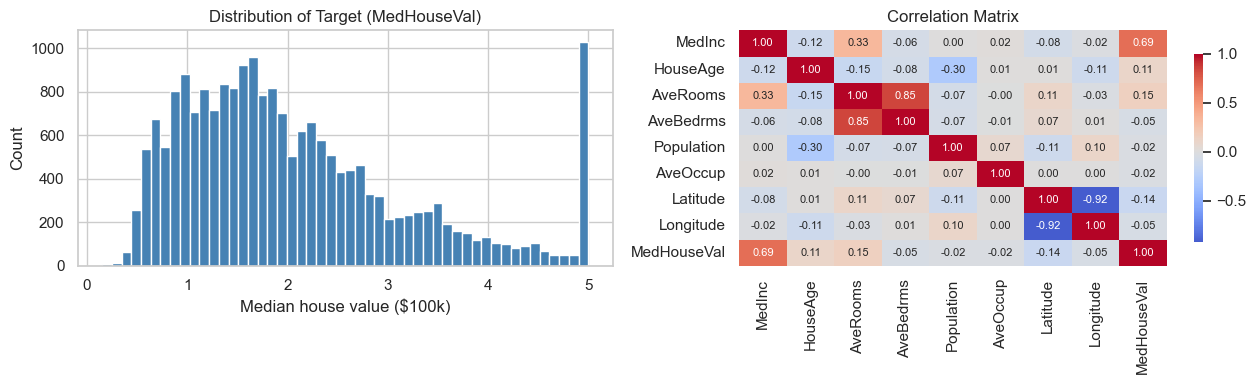

In [6]:
# Distribution of the target and correlations
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["MedHouseVal"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Target (MedHouseVal)")
axes[0].set_xlabel("Median house value ($100k)")
axes[0].set_ylabel("Count")

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1],
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
axes[1].set_title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [7]:
X = df.drop(columns=["MedHouseVal"])   # input features
y = df["MedHouseVal"]                   # continuous target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (16512, 8) | X_test: (4128, 8)
y_train: (16512,) | y_test: (4128,)


In [8]:
# Optional feature engineering: bedrooms-per-room ratio
X_train = X_train.copy()
X_test = X_test.copy()
X_train["BedrmsPerRoom"] = X_train["AveBedrms"] / X_train["AveRooms"]
X_test["BedrmsPerRoom"] = X_test["AveBedrms"] / X_test["AveRooms"]

# Feature scaling — fit ONLY on training data to prevent leakage
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

X_train_scaled.describe().T[["mean", "std"]].round(3)

,mean,std
MedInc,-0.0,1.0
HouseAge,-0.0,1.0
AveRooms,-0.0,1.0
AveBedrms,-0.0,1.0
Population,-0.0,1.0
AveOccup,0.0,1.0
Latitude,0.0,1.0
Longitude,0.0,1.0
BedrmsPerRoom,-0.0,1.0


In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso (alpha=0.001)": Lasso(alpha=0.001, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

def evaluate(model, X_tr, y_tr, X_te, y_te):
    """Fit a model and return train/test metrics: MAE, MSE, RMSE, R²."""
    model.fit(X_tr, y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    def metrics(y_true, y_pred):
        mae = mean_absolute_error(y_true, y_pred)
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_true, y_pred)
        return mae, mse, rmse, r2

    return metrics(y_tr, pred_tr), metrics(y_te, pred_te), pred_te

results = []
test_predictions = {}

for name, model in models.items():
    (tr_mae, tr_mse, tr_rmse, tr_r2), (te_mae, te_mse, te_rmse, te_r2), pred_te = \
        evaluate(model, X_train_scaled, y_train, X_test_scaled, y_test)
    test_predictions[name] = pred_te
    results.append({
        "Model": name,
        "MAE (test)": te_mae, "MSE (test)": te_mse,
        "RMSE (test)": te_rmse, "R² (test)": te_r2,
        "RMSE (train)": tr_rmse, "R² (train)": tr_r2,
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,MAE (test),MSE (test),RMSE (test),R² (test),RMSE (train),R² (train)
Model,,,,,,
Linear Regression,0.5261,0.5317,0.7292,0.5942,0.7137,0.6190
Ridge (alpha=1.0),0.5261,0.5317,0.7292,0.5942,0.7137,0.6190
Lasso (alpha=0.001),0.5260,0.5318,0.7293,0.5941,0.7137,0.6189
Decision Tree,0.4536,0.4907,0.7005,0.6255,0.0000,1.0000
Random Forest,0.3278,0.2543,0.5043,0.8059,0.1860,0.9741
Gradient Boosting,0.3675,0.2892,0.5378,0.7793,0.5056,0.8088


In [10]:
# Sorted metric table (best test RMSE first)
results_df.sort_values("RMSE (test)").round(4)

,MAE (test),MSE (test),RMSE (test),R² (test),RMSE (train),R² (train)
Model,,,,,,
Random Forest,0.3278,0.2543,0.5043,0.8059,0.1860,0.9741
Gradient Boosting,0.3675,0.2892,0.5378,0.7793,0.5056,0.8088
Decision Tree,0.4536,0.4907,0.7005,0.6255,0.0000,1.0000
Ridge (alpha=1.0),0.5261,0.5317,0.7292,0.5942,0.7137,0.6190
Linear Regression,0.5261,0.5317,0.7292,0.5942,0.7137,0.6190
Lasso (alpha=0.001),0.5260,0.5318,0.7293,0.5941,0.7137,0.6189


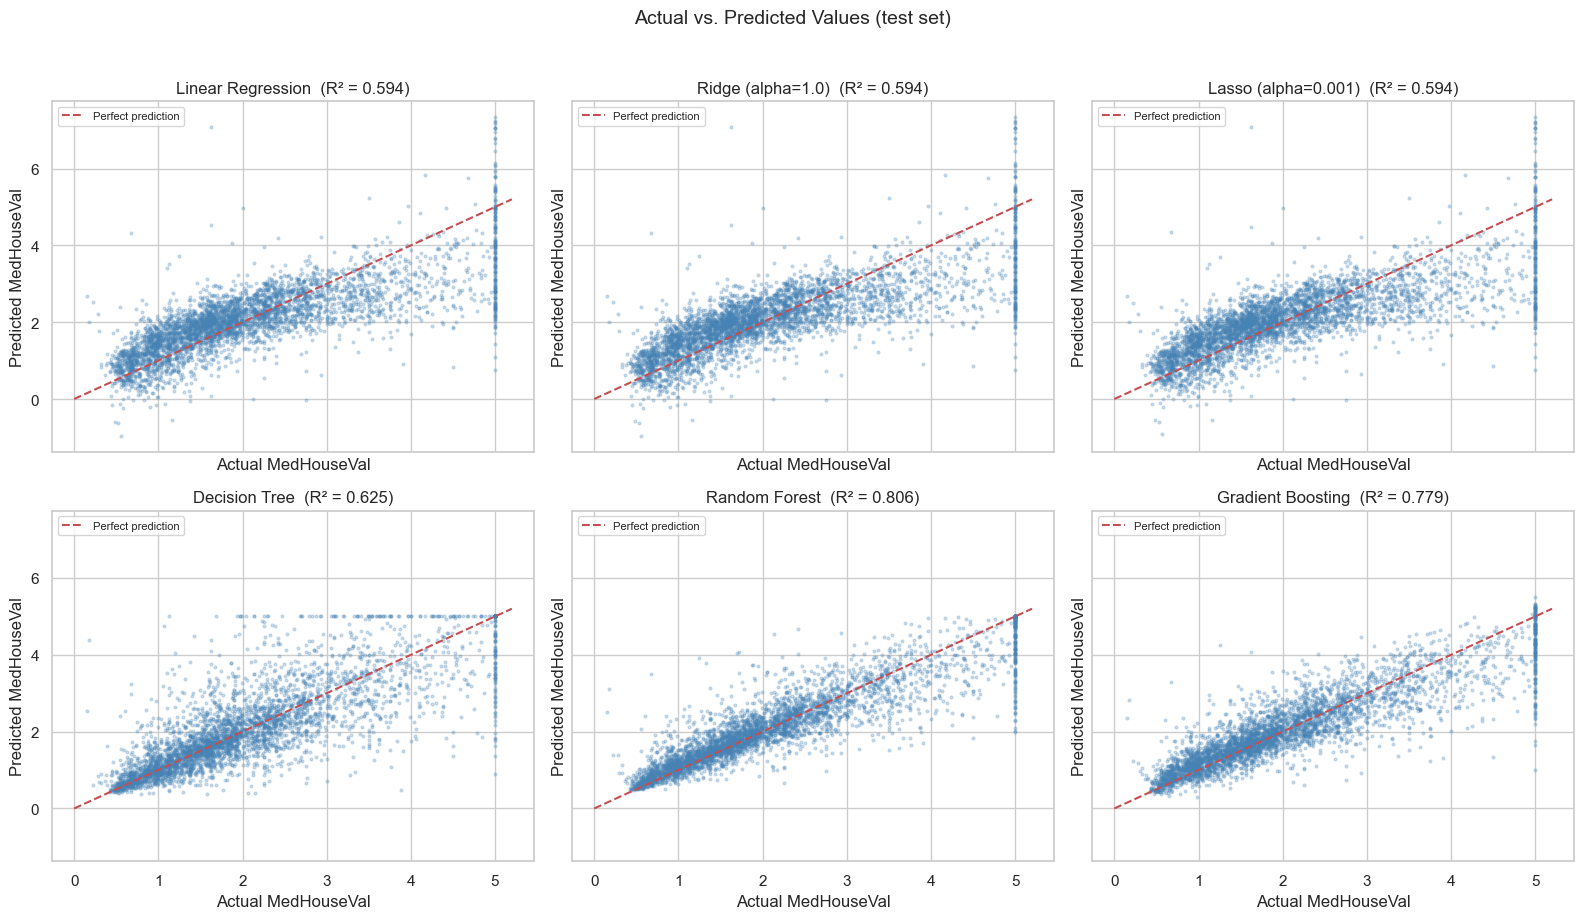

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)

for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    ax.scatter(y_test, pred, s=4, alpha=0.25, color="steelblue")
    lims = [0, 5.2]
    ax.plot(lims, lims, "r--", linewidth=1.5, label="Perfect prediction")
    r2 = r2_score(y_test, pred)
    ax.set_title(f"{name}  (R² = {r2:.3f})")
    ax.set_xlabel("Actual MedHouseVal")
    ax.set_ylabel("Predicted MedHouseVal")
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Actual vs. Predicted Values (test set)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

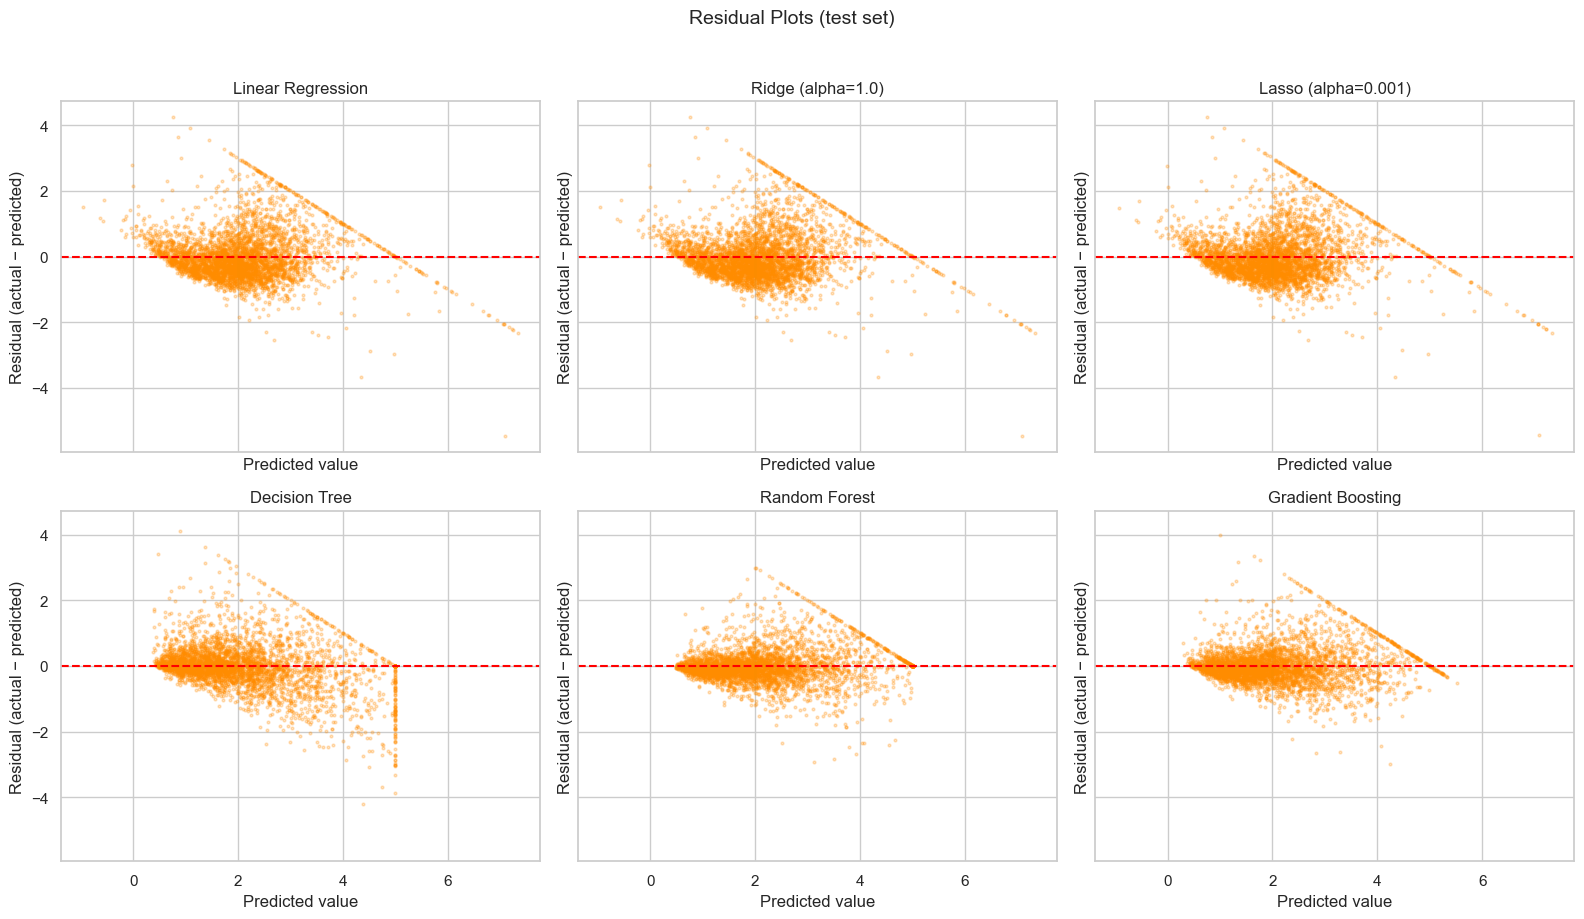

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)

for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    residuals = y_test - pred
    ax.scatter(pred, residuals, s=4, alpha=0.25, color="darkorange")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual (actual − predicted)")

plt.suptitle("Residual Plots (test set)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

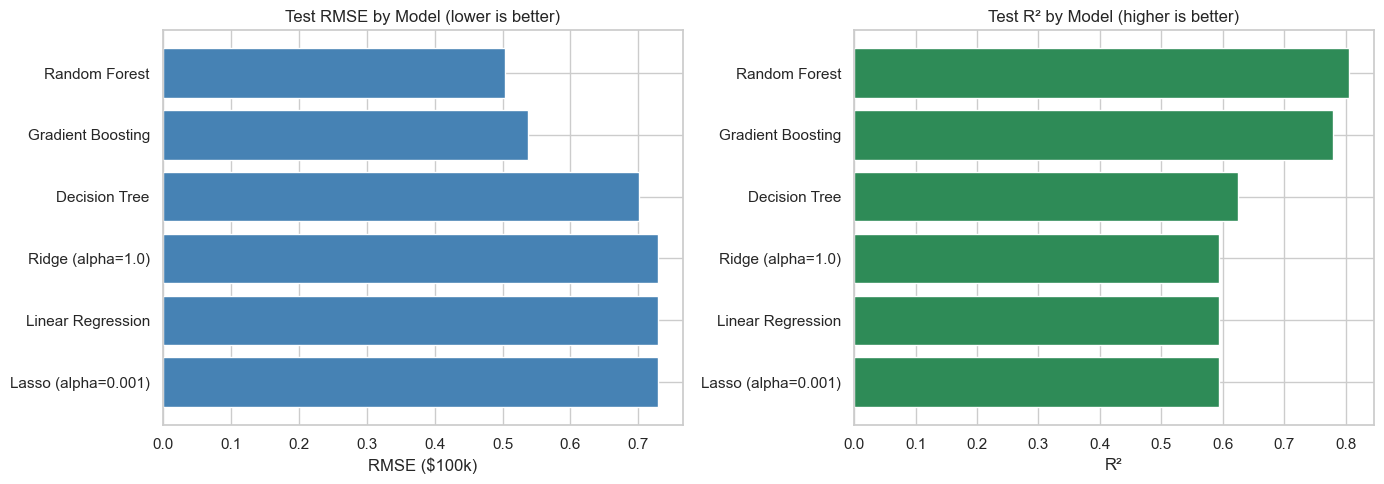

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = results_df.sort_values("RMSE (test)").index

axes[0].barh(order, results_df.loc[order, "RMSE (test)"], color="steelblue")
axes[0].set_title("Test RMSE by Model (lower is better)")
axes[0].set_xlabel("RMSE ($100k)")
axes[0].invert_yaxis()

axes[1].barh(order, results_df.loc[order, "R² (test)"], color="seagreen")
axes[1].set_title("Test R² by Model (higher is better)")
axes[1].set_xlabel("R²")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

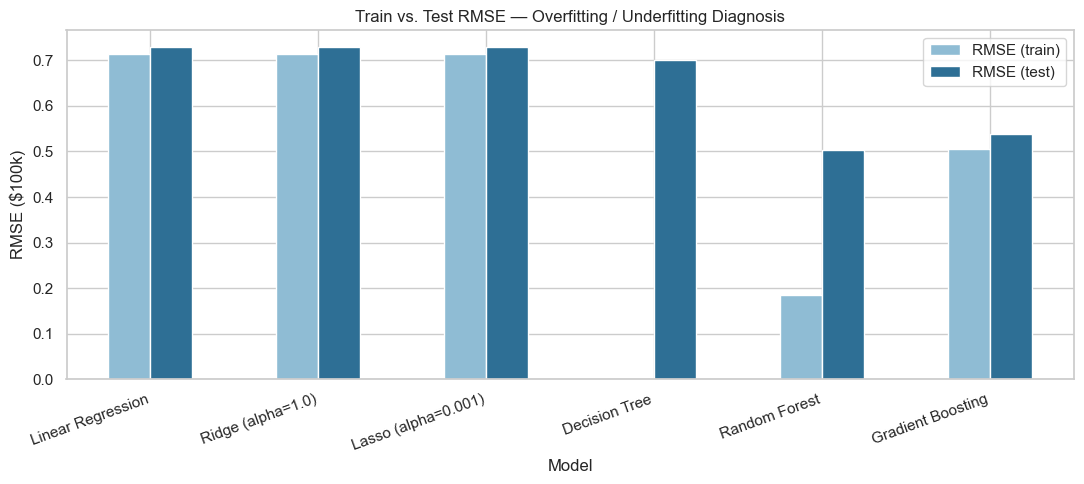

,RMSE (train),RMSE (test),Gap (test − train)
Model,,,
Linear Regression,0.7137,0.7292,0.0155
Ridge (alpha=1.0),0.7137,0.7292,0.0155
Lasso (alpha=0.001),0.7137,0.7293,0.0155
Decision Tree,0.0000,0.7005,0.7005
Random Forest,0.1860,0.5043,0.3183
Gradient Boosting,0.5056,0.5378,0.0322


In [14]:
gap_df = results_df[["RMSE (train)", "RMSE (test)"]].copy()
gap_df["Gap (test − train)"] = gap_df["RMSE (test)"] - gap_df["RMSE (train)"]

ax = gap_df[["RMSE (train)", "RMSE (test)"]].plot(
    kind="bar", figsize=(11, 5), color=["#8fbcd4", "#2e6f95"], edgecolor="white"
)
ax.set_title("Train vs. Test RMSE — Overfitting / Underfitting Diagnosis")
ax.set_ylabel("RMSE ($100k)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

gap_df.round(4)

Final Conclusion:-

Out of all the models Random Forest performed the best with lowest RMSE score of around 0.5 and R2 score of around 0.80. This explains that there is 80% of variance in house values with typical error of about $50k. Gradient Boosting came a close second.

The Linear Models all got R2 score of around 0.60. They underfitted because the relationship between features like income and location and house prices is non-linear. The single decision tree hit near zero training error but much worse test error showing clear signs of overfitting. 

Random Forest model wins because it captures the non-linear paterns and feature interaction like income and locaiton that the linear models missed, while averaging many trees controls the overfitting that a single tree suffered from.  